In [ ]:
import pandas as pd
import numpy as np
import torch
import re
import warnings
import logging
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter

from imblearn.over_sampling import SMOTE

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

from torch.utils.data import DataLoader
warnings.filterwarnings("ignore")
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

In [ ]:
dataset = load_dataset("rasyosef/amharic-sentiment")

train_df = pd.DataFrame(dataset["train"])
valid_df = pd.DataFrame(dataset["dev"])
test_df = pd.DataFrame(dataset["test"])

print("Train shape:", train_df.shape)
print("Validation shape:", valid_df.shape)
print("Test shape:", test_df.shape)
print(train_df.head())

Train shape: (2223, 2)
Validation shape: (279, 2)
Test shape: (279, 2)
                                         clean_tweet  label
0  አሜን እውነት ብለሀል መሪዬ ዶር ዐብይ ብዙዎች ከአንተጋር መሆናችንን እን...      1
1  እወድሽ ነበረ ዛሬስ ጠላሁሽ\n እንደ ሰፌድ ቆሎ ያም ያም ዘገነሽ፧\nወይ ጉድ      0
2      😂😆😜🤡 አጋር ፓርቲም ሆኖ የመኖር ፍላጎት አሳይታለች....አሮጊቷ 🙌🏽🤣      0
3  ከፍተኛ ሊግ ለ | መከላከያ እና ሀምበሪቾ ወደ ሠንጠረዡ አናት ሲጠጉ ሶዶ...      1
4                   ይሄ ሽማግሌ ግን አይበቃውም? ንስሃ አይገባም🤦‍♂️      0


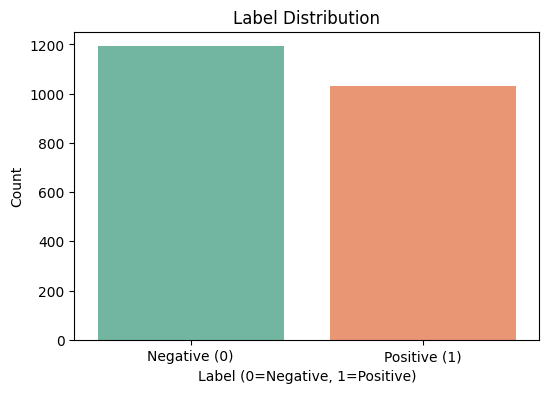

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x="label", palette="Set2")
plt.title("Label Distribution")
plt.xlabel("Label (0=Negative, 1=Positive)")
plt.ylabel("Count")
plt.xticks([0, 1], ["Negative (0)", "Positive (1)"])
plt.show()



In [ ]:
import re

def normalize_amharic(text: str) -> str:
    replacements = {

        r'[ሐኀኻ]': 'ሀ', r'[ሑኁዅ]': 'ሁ', r'[ሒኂኺ]': 'ሂ',
        r'[ሓኃኻ]': 'ሃ', r'[ሔኄኼ]': 'ሄ', r'[ሕኅኽ]': 'ህ', r'[ሖኆኾ]': 'ሆ',

        r'ሠ': 'ሰ', r'ሡ': 'ሱ', r'ሢ': 'ሲ', r'ሣ': 'ሳ', r'ሤ': 'ሴ', r'ሥ': 'ስ', r'ሦ': 'ሶ',

        r'ዐ': 'አ', r'ዑ': 'ኡ', r'ዒ': 'ኢ', r'ዓ': 'ኣ', r'ዔ': 'ኤ', r'ዕ': 'እ', r'ዖ': 'ኦ',

        r'ፀ': 'ጸ', r'ፁ': 'ጹ', r'ጺ': 'ጺ', r'ፃ': 'ጻ', r'ፄ': 'ጼ', r'ፅ': 'ጽ', r'ፆ': 'ጾ',
    }

    for pattern, replacement in replacements.items():
        text = re.sub(pattern, replacement, text)

    # 4. Whitespace cleanup
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
def clean_amharic_text(text: str) -> str:
    # 2. Normalize Amharic variants
    text = normalize_amharic(text)

    # 3. Remove URLs & emails
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"\S+@\S+", "", text)

    # 4. Remove mentions & hashtags
    text = re.sub(r"[@#]\S+", "", text)

    # 5. Remove emojis
    text = re.sub(
        r"[\U00010000-\U0010ffff]",
        "",
        text,
        flags=re.UNICODE
    )

    # 6. Remove numbers (Arabic & Ethiopic)
    text = re.sub(r"[0-9፩-፻]", "", text)

    # 7. Keep only Amharic + punctuation
    text = re.sub(
        r"[^\u1200-\u137F\s.,!?።፣፤፥፧፦]",
        "",
        text
    )

    # 8. Normalize repeated punctuation
    text = re.sub(r"([!?።፣፤፥፧፦])\1+", r"\1", text)

    # 9. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [ ]:
for df in [train_df, valid_df, test_df]:
    df["clean_tweet"] = df["clean_tweet"].astype(str).apply(clean)


In [ ]:
MIN_TOKENS = 2
initial_len = len(train_df)
train_df = train_df[train_df["clean_tweet"].apply(
lambda x: len(x.split()) >= MIN_TOKENS)]
print(f"Removed {initial_len - len(train_df)} short samples")

Removed 8 short samples


In [ ]:
vectorizer = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    norm="l2"
)

X_train_vec = vectorizer.fit_transform(train_df["clean_tweet"])
y_train = train_df["label"]

print("Before SMOTE:", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_vec, y_train)

print("After SMOTE:", Counter(y_train_smote))


Before SMOTE: Counter({0: 1189, 1: 1026})
After SMOTE: Counter({1: 1189, 0: 1189})


In [ ]:
indices = np.arange(X_train_smote.shape[0])
original_texts = train_df["clean_tweet"].tolist()

synthetic_texts = []
for i in indices:
    if i < len(original_texts):
        synthetic_texts.append(original_texts[i])
    else:
        synthetic_texts.append(original_texts[i % len(original_texts)])

train_smote_df = pd.DataFrame({
    "clean_tweet": synthetic_texts,
    "label": y_train_smote
})


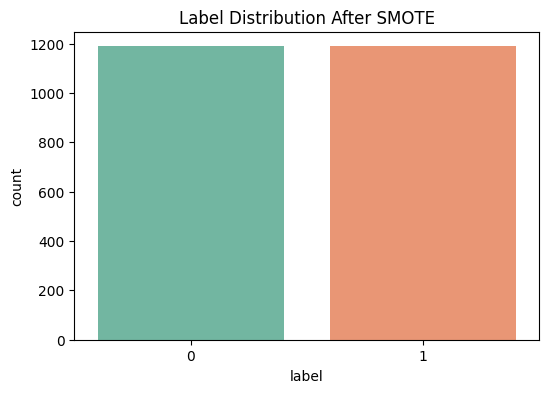

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_smote_df, x="label", palette="Set2")
plt.title("Label Distribution After SMOTE")
plt.show()



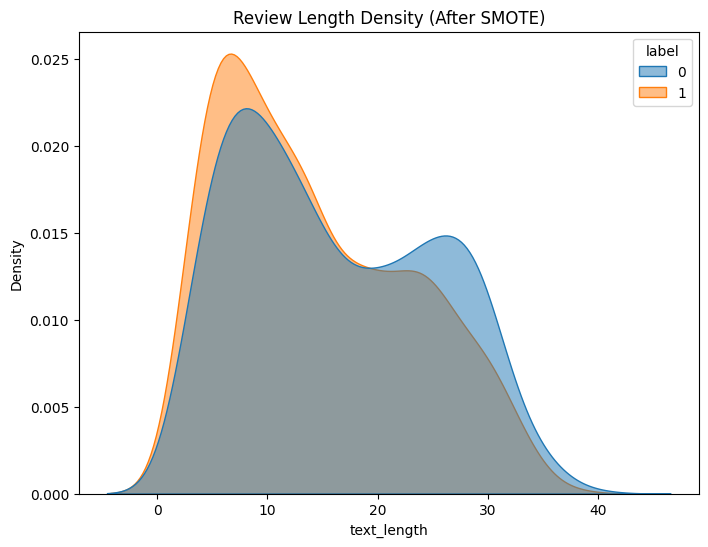

In [ ]:
train_smote_df["text_length"] = train_smote_df["clean_tweet"].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 6))
sns.kdeplot(data=train_smote_df, x="text_length", hue="label", fill=True, alpha=0.5)
plt.title("Review Length Density (After SMOTE)")
plt.show()

In [ ]:
model_name = "rasyosef/bert-small-amharic"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(batch):
    return tokenizer(
        batch["clean_tweet"],
        truncation=True,
        padding="max_length",
        max_length=40
    )


In [ ]:
train_dataset = Dataset.from_pandas(train_smote_df)
valid_dataset = Dataset.from_pandas(valid_df)
test_dataset = Dataset.from_pandas(test_df)

train_tok = train_dataset.map(tokenize_function, batched=True)
valid_tok = valid_dataset.map(tokenize_function, batched=True)
test_tok = test_dataset.map(tokenize_function, batched=True)

train_tok.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
valid_tok.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
test_tok.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

Map:   0%|          | 0/2378 [00:00<?, ? examples/s]

Map:   0%|          | 0/279 [00:00<?, ? examples/s]

Map:   0%|          | 0/279 [00:00<?, ? examples/s]

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
).to(device)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at rasyosef/bert-small-amharic and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, preds)}

In [ ]:
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    weight_decay=0.01,
    logging_dir="./logs",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=valid_tok,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.594300,0.430801,0.810036
2,0.419800,0.421563,0.838710
3,0.327800,0.462509,0.806452
4,0.262100,0.458394,0.835125
5,0.205100,0.511050,0.835125
6,0.183700,0.571006,0.810036
7,0.150000,0.562310,0.835125
8,0.158000,0.575366,0.827957
9,0.143100,0.582445,0.827957
10,0.114000,0.575091,0.824373


TrainOutput(global_step=750, training_loss=0.25152154858907066, metrics={'train_runtime': 73.539, 'train_samples_per_second': 323.366, 'train_steps_per_second': 10.199, 'total_flos': 117561398307840.0, 'train_loss': 0.25152154858907066, 'epoch': 10.0})

In [ ]:
test_output = trainer.predict(test_tok)
test_preds = np.argmax(test_output.predictions, axis=1)
test_labels = test_output.label_ids

test_acc = accuracy_score(test_labels, test_preds)
print(f"\nTest Accuracy: {test_acc:.4f}")

print("\nClassification Report:")
print(classification_report(test_labels, test_preds))


Test Accuracy: 0.8244

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       150
           1       0.82      0.79      0.81       129

    accuracy                           0.82       279
   macro avg       0.82      0.82      0.82       279
weighted avg       0.82      0.82      0.82       279



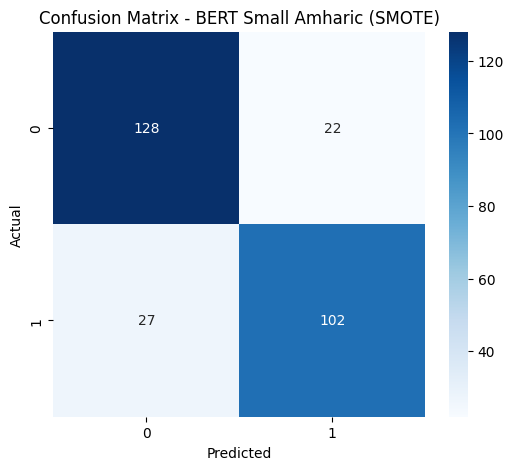

In [ ]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - BERT Small Amharic (SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
!pip install datasets

In [ ]:
!pip install etnltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.1 MB/s eta 0:00:00
